# Big Data e IA · DAM2 · 27 octubre
**Nombre y apellidos:** 

Gitbook: *Unidad 1 → APIs y JSON → Ejemplo API Ayuntamiento* y *Actividad 15: Análisis API*

---
# Parte 1 · Ejemplo API Ayuntamiento (Bizi Zaragoza)
Copia el código que escribe el profesor en cada celda y ejecútalo.

## Celda 1 · Descargar el JSON de Bizi

In [2]:
import requests
import pandas as pd

# Endpoint oficial Open Data Zaragoza
ZGZ_URL = "https://www.zaragoza.es/sede/servicio/urbanismo-infraestructuras/estacion-bicicleta.json"
params = {"rows": 200}

# Descargar JSON
resp = requests.get(ZGZ_URL, params=params, timeout=15)
resp.raise_for_status()
data = resp.json()

# Saber que datos tenemos:
print(type(data))
list(data.keys())


<class 'dict'>


['totalCount', 'start', 'rows', 'result']

## Celda 2 · ¿Están todas las estaciones? (`len` vs `totalCount`)

In [ ]:
# Sabemos que la clave "result" contiene las estaciones
rows = data["result"]   # lista de dicts

print("Descargadas: " , len(data["result"])) #Comprobar que tengamos todas las estaciones
print("Existen: ", data["totalCount"])

# Crear DataFrame
df_bici = pd.DataFrame(rows)

## Celda 3 · DataFrame: `shape`, `columns`, `dtypes`, `head`

In [17]:
print("=== Características del DataFrame ===")
print("shape:", df_bici.shape) # rows x columns 
print("columnas:", df_bici.columns.tolist()) #pone las columnas ordenas
print("\n.dtypes:\n", df_bici.dtypes.head(10)) #
print("\n.head():\n", df_bici.head(3)) # 



=== Características del DataFrame ===
shape: (200, 14)
columnas: ['id', 'about', 'title', 'estado', 'estadoEstacion', 'address', 'tipoEquipamiento', 'bicisDisponibles', 'anclajesDisponibles', 'geometry', 'lastUpdated', 'description', 'descripcion', 'icon']

.dtypes:
 id                        str
about                     str
title                     str
estado                    str
estadoEstacion            str
address                   str
tipoEquipamiento          str
bicisDisponibles        int64
anclajesDisponibles     int64
geometry               object
dtype: object

.head():
     id                                              about  \
0  279  http://www.zaragoza.es/ciudad/viapublica/movil...   
1  278  http://www.zaragoza.es/ciudad/viapublica/movil...   
2  277  http://www.zaragoza.es/ciudad/viapublica/movil...   

                           title      estado  \
0            193- Pza. La Ermita  IN_SERVICE   
1        270- Delicias Autobuses  IN_SERVICE   
2  150- Mrio. Sire

## Celda 4 · Filtros con una condición, con Y (`&`) y con O (`|`)

In [ ]:
# --- Filtrar estaciones con bicis disponibles (>0) ---
if "bicisDisponibles" in df_bici.columns:
    chuecaMoviles_libres = df_bici[df_bici["bicisDisponibles"] > 0] # guardo valores true/falso que comparo primeramente con el 0 y luego con el df og 

    print("\n=== Estaciones con chueca moviles disponibles ===")
    print(df_libres[["title", "bicisDisponibles", "anclajesDisponibles"]].head(10))
else:
    print("\nLa columna 'bicisDisponibles' no está disponible en este JSON, revisa columnas exactas.")

filtro_Condicion = df_bici["bicisDisponibles"]>0
print("estaciones con chueca moviles: ", filtro_Condicion.sum())

filtro_Otra_Condicion = (df_bici["bicisDisponibles"]>0) & (df_bici["anclajesDisponibles"]>0)
print("Estaciones con chueca moviles y chueca-parkings: ", filtro_Condicion.sum())


=== Estaciones con chueca moviles disponibles ===
                            title  bicisDisponibles  anclajesDisponibles
2   150- Mrio. Siresa: Dr. Iranzo                 4                   14
3             127- Navarra: Rioja                 2                   17
4     20- Camón Aznar: C. Augusto                 8                   11
5        190- Puerto Venecia Este                19                   21
6               224- Manuel Viola                 7                   11
7       189- Puerto Venecia Oeste                 3                   36
9           22- Delicias Llegadas                 1                   18
10       263- Avda. Real Zaragoza                 1                   18
11            147- Norte: Iglesia                 2                   17
12    144- Ostáriz Forcén: Brazal                11                    7
estaciones con chueca moviles:  164
Estaciones con chueca moviles y chueca-parkings:  164


## Celda 5 · Gráfico de barras: top 10 estaciones con más bicis

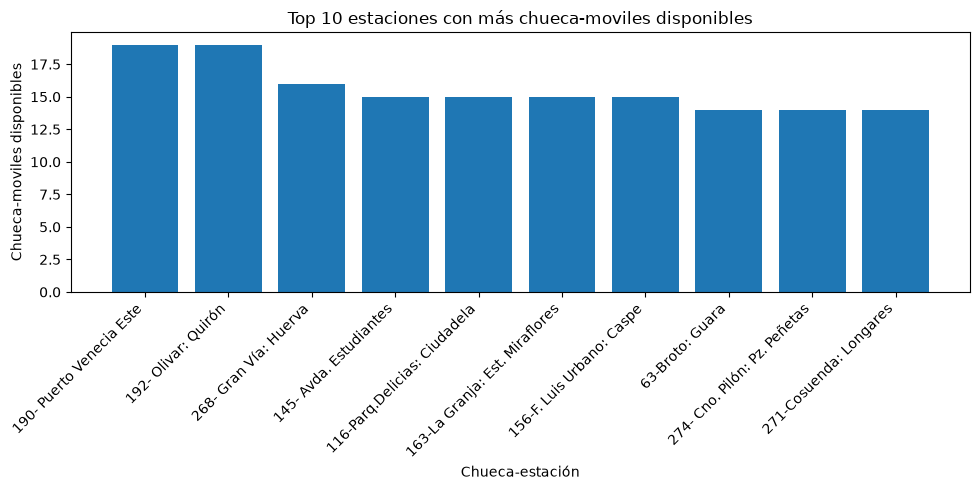

,title,bicisDisponibles,anclajesDisponibles
5,190- Puerto Venecia Este,19,21
43,192- Olivar: Quirón,19,0
140,268- Gran Vía: Huerva,16,2
17,145- Avda. Estudiantes,15,3
171,116-Parq.Delicias: Ciudadela,15,3
118,163-La Granja: Est. Miraflores,15,3
109,156-F. Luis Urbano: Caspe,15,4
99,63-Broto: Guara,14,5
63,274- Cno. Pilón: Pz. Peñetas,14,5
104,271-Cosuenda: Longares,14,4


In [28]:
import matplotlib.pyplot as plt

# Filtrar estaciones con > 0 bicis disponibles
df_libres = df_bici[df_bici["bicisDisponibles"] > 0].copy()

# Ordenar y tomar top 10
top10 = df_libres.sort_values("bicisDisponibles", ascending=False).head(10)

# Preparar ejes
x = top10["title"]
y = top10["bicisDisponibles"]

plt.figure(figsize=(10, 5))
plt.bar(x, y)
plt.title("Top 10 estaciones con más chueca-moviles disponibles")
plt.xlabel("Chueca-estación")
plt.ylabel("Chueca-moviles disponibles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# (Opcional) Mostrar la tabla que alimenta el gráfico
top10[["title", "bicisDisponibles", "anclajesDisponibles"]]


## Celda 6 · Coordenadas (`geometry`) y mapa de dispersión

In [6]:
# Tu código aquí


**Pregunta:** ¿qué estructura tiene el JSON de Bizi? Compárala con CoinGecko y Binance.

*Respuesta:* 